<a href="https://colab.research.google.com/github/Tanuja-code125/Applied-ML-Lab/blob/main/Experiment_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Risk Assessment: Build a credit scoring model to assess the creditworthiness of applicants using historical financial data and perform comparative analysis (Logistic Regression, Random Forest)

#Step 1 — Import libraries

In [ ]:
import pandas as pd
import numpy as np

from  sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix)

import matplotlib.pyplot as plt
import seaborn as sns


#Step 2 — Load and explore the data

In [ ]:
df=pd.read_csv("/content/credit_risk_assessment_500_samples.csv")

# first five row
display(df.head())

# number of total row and column show
print("\n Dataset shape : ", df.shape)

# Column
print(" \n Columns : ", df.columns)

,Applicant_ID,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Loan_Term_Months,Existing_Loans_Count,Debt_to_Income_Ratio,Late_Payments_Last_2Yrs,Credit_Risk
0,1,59,153267,28,818,196649,12,2,0.68,0,High
1,2,49,232745,0,436,175354,60,0,0.23,5,High
2,3,35,974945,19,797,662297,48,3,0.54,0,Medium
3,4,63,307164,29,776,831725,48,0,0.56,4,High
4,5,28,685626,6,893,498625,60,3,0.66,8,High



 Dataset shape :  (500, 11)
 
 Columns :  Index(['Applicant_ID', 'Age', 'Annual_Income', 'Employment_Years',
       'Credit_Score', 'Loan_Amount', 'Loan_Term_Months',
       'Existing_Loans_Count', 'Debt_to_Income_Ratio',
       'Late_Payments_Last_2Yrs', 'Credit_Risk'],
      dtype='object')


#Step 3 — Handle Missing Values

In [ ]:
# handle null value
print("\n Missing Values :")
print(df.isnull().sum())

print("\n Statistical summary :")
display(df.describe())

#drop null value
df= df.dropna()
print("Dataset shape after cleaning : ", df.shape)




 Missing Values :
Applicant_ID               0
Age                        0
Annual_Income              0
Employment_Years           0
Credit_Score               0
Loan_Amount                0
Loan_Term_Months           0
Existing_Loans_Count       0
Debt_to_Income_Ratio       0
Late_Payments_Last_2Yrs    0
Credit_Risk                0
dtype: int64

 Statistical summary :


,Applicant_ID,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Loan_Term_Months,Existing_Loans_Count,Debt_to_Income_Ratio,Late_Payments_Last_2Yrs
count,500.000000,500.000000,5.000000e+02,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,250.500000,43.116000,8.271317e+05,14.702000,596.394000,521385.530000,37.032000,2.058000,0.409700,4.490000
std,144.481833,12.733217,3.848299e+05,8.713498,171.339795,281799.514154,17.117037,1.419389,0.175077,2.940611
min,1.000000,21.000000,1.504040e+05,0.000000,300.000000,55901.000000,12.000000,0.000000,0.100000,0.000000
25%,125.750000,32.000000,5.062622e+05,7.000000,452.000000,266621.750000,24.000000,1.000000,0.250000,2.000000
50%,250.500000,44.000000,8.334275e+05,15.500000,602.000000,533640.000000,36.000000,2.000000,0.420000,5.000000
75%,375.250000,53.000000,1.148353e+06,22.000000,732.250000,765362.500000,48.000000,3.000000,0.560000,7.000000
max,500.000000,64.000000,1.498464e+06,29.000000,898.000000,999621.000000,60.000000,4.000000,0.700000,9.000000


Dataset shape after cleaning :  (500, 11)


# Step 4 — Select features and target

In [ ]:
X = df.drop(columns=["Applicant_ID", "Credit_Risk"])
y = df['Credit_Risk']

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\n Risk categgories :")
print(y.value_counts())



Input features shape: (500, 9)
Target shape: (500,)

 Risk categgories :
Credit_Risk
High      315
Medium    164
Low        21
Name: count, dtype: int64


#Step 5 — Use NumPy to inspect numerical data

In [ ]:
X_array = X.to_numpy()
y_array = y.to_numpy()

print("Numpy input array Shape" , X_array.shape)
print("Numpy target array Shape" , y_array.shape)

print("\n First applicant's features:")
print(X_array[0])

print("\n First applicant's risk:")
print(y_array[0])



Numpy input array Shape (500, 9)
Numpy target array Shape (500,)

 First applicant's features:
[5.90000e+01 1.53267e+05 2.80000e+01 8.18000e+02 1.96649e+05 1.20000e+01
 2.00000e+00 6.80000e-01 0.00000e+00]

 First applicant's risk:
High


#Step 6 — Split training and testing data

In [ ]:
X_train, X_test ,y_train,y_test = train_test_split(X , y ,
                                                  test_size = 0.20 ,
                                                  random_state = 42 ,
                                                  stratify = y)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


#Step 7 — Create both models

In [ ]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

# Train and evaluate the models


Model: Logistic Regression
Accuracy: 82.0 %

Classification Report:
              precision    recall  f1-score   support

        High       0.91      0.84      0.88        63
         Low       0.67      0.50      0.57         4
      Medium       0.69      0.82      0.75        33

    accuracy                           0.82       100
   macro avg       0.76      0.72      0.73       100
weighted avg       0.83      0.82      0.82       100

Confusion Matrix:
[[ 2  2  0]
 [ 1 27  5]
 [ 0 10 53]]


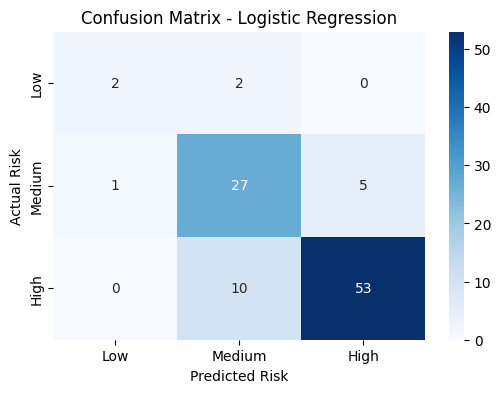


Model: Random Forest
Accuracy: 98.0 %

Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        63
         Low       1.00      0.50      0.67         4
      Medium       0.94      1.00      0.97        33

    accuracy                           0.98       100
   macro avg       0.98      0.83      0.88       100
weighted avg       0.98      0.98      0.98       100

Confusion Matrix:
[[ 2  2  0]
 [ 0 33  0]
 [ 0  0 63]]


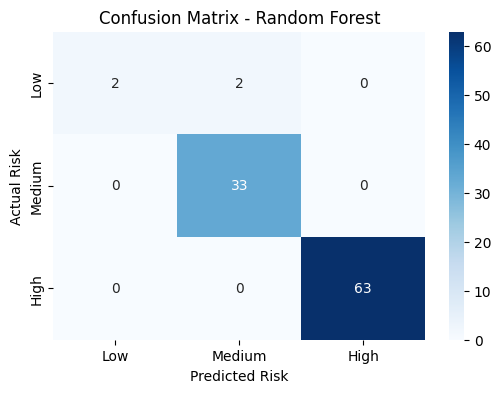

In [ ]:
result = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Convert predictions into a NumPy array
    y_pred_array = np.array(y_pred)

    accuracy = accuracy_score(y_test, y_pred_array)
    result[name] = accuracy

    print("\nModel:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred_array,
        zero_division=0
    ))

    labels = ["Low", "Medium", "High"]

    cm = confusion_matrix(
        y_test,
        y_pred_array,
        labels=labels
    )

    print("Confusion Matrix:")
    print(cm)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title("Confusion Matrix - " + name)
    plt.xlabel("Predicted Risk")
    plt.ylabel("Actual Risk")
    plt.show()

#Step 9 — Compare the models

In [ ]:
comparison = pd.DataFrame({
    "Model": list(result.keys()),
    "Accuracy": list(result.values())
})

comparison["Accuracy (%)"] = (
    np.round(comparison["Accuracy"] * 100, 2)
)

display(comparison[["Model", "Accuracy (%)"]])

best_model = comparison.loc[
    comparison["Accuracy"].idxmax(), "Model"
]

print("Best model:", best_model)

,Model,Accuracy (%)
0,Logistic Regression,82.0
1,Random Forest,98.0


Best model: Random Forest
